# Segunda etapa Gold — análise estatística do Churn

Notebook independente e complementar às oito perguntas de `03_analise_gold.ipynb`. Usa somente `bases/silver/base_silver.csv`; não altera Bronze nem Silver. Cada taxa mostra cancelamentos, total do grupo e percentual, com IC de 95% Wilson para proporções. As relações descritas são associações, não causas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd()
if not (RAIZ / 'bases' / 'silver' / 'base_silver.csv').exists():
    RAIZ = RAIZ.parent
CAMINHO_SILVER = RAIZ / 'bases' / 'silver' / 'base_silver.csv'
DIR_TABELAS = RAIZ / 'bases' / 'gold' / 'tabelas'
DIR_GRAFICOS = RAIZ / 'bases' / 'gold' / 'graficos'
DIR_TABELAS.mkdir(parents=True, exist_ok=True)
DIR_GRAFICOS.mkdir(parents=True, exist_ok=True)

dados = pd.read_csv(CAMINHO_SILVER, dtype={'tenure': 'Int64'})
assert len(dados) == 5634, f'Tamanho inesperado da Silver: {len(dados)}'
assert set(dados['Churn'].dropna().unique()) <= {'Yes', 'No'}
sns.set_theme(style='whitegrid', palette='colorblind')
print(f'Fonte Silver: {CAMINHO_SILVER}')
print(f"N={len(dados):,}; cancelamentos={(dados['Churn'] == 'Yes').sum():,}; sem cancelamento={(dados['Churn'] == 'No').sum():,}")
print(f"tenure ausente={dados['tenure'].isna().sum():,}; TotalCharges imputado={dados['TotalCharges_imputado'].sum():,}")

Fonte Silver: C:\Users\52384154869\Documents\projeto-integrador-databricks\bases\silver\base_silver.csv
N=5,634; cancelamentos=1,504; sem cancelamento=4,130
tenure ausente=19; TotalCharges imputado=277


## Método para taxas e intervalos

O intervalo de Wilson de 95% expressa a incerteza de uma proporção, como a taxa de churn. Ele não é uma margem de erro para qualquer medida nem prova causalidade. O método mantém limites entre 0% e 100% e funciona melhor que a aproximação normal simples em grupos pequenos ou proporções próximas aos extremos.

,escopo,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct
0,Todos os clientes,5634,1504,26.7,25.56,27.87


,Churn,n,media,mediana,desvio_padrao,cancelamentos,total_grupo
0,No,4130,60.96,64.35,31.09,0,4130
1,Yes,1504,74.63,79.82,24.81,1504,1504


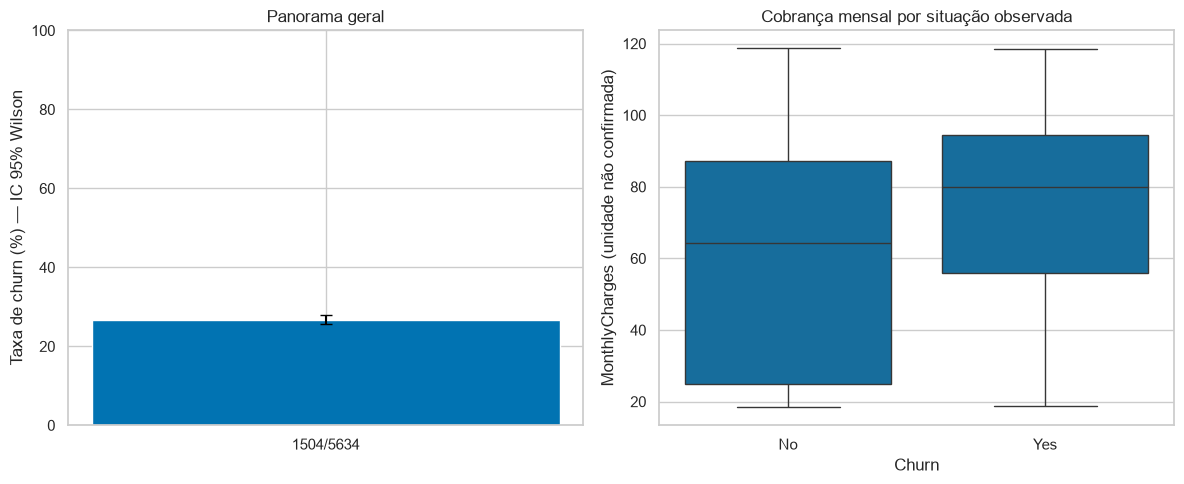

N válido para tenure=5,615; excluídos por tenure ausente=19.


,faixa_tenure,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct
0,0-6,1176,616,52.38,49.52,55.22
1,7-12,575,203,35.30,31.51,39.30
2,13-24,805,229,28.45,25.44,31.66
3,25-48,1289,280,21.72,19.56,24.06
4,49-72,1770,168,9.49,8.21,10.95


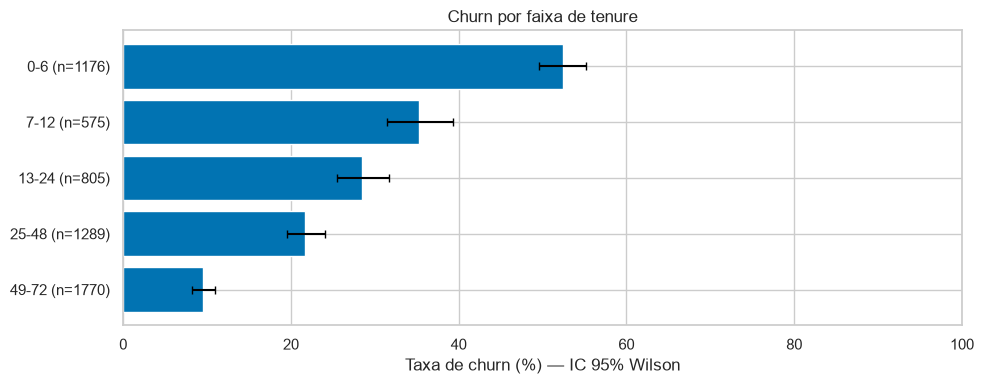

,faixa_tenure,Contract,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct
0,0-6,Month-to-month,1119,612,54.69,51.76,57.59
1,0-6,One year,34,4,11.76,4.67,26.62
2,0-6,Two year,23,0,0.00,0.00,14.31
3,7-12,Month-to-month,470,195,41.49,37.12,46.00
4,7-12,One year,71,8,11.27,5.82,20.69
5,7-12,Two year,34,0,0.00,0.00,10.15
6,13-24,Month-to-month,569,217,38.14,34.24,42.20
7,13-24,One year,157,12,7.64,4.43,12.88
8,13-24,Two year,79,0,0.00,0.00,4.64
9,25-48,Month-to-month,657,227,34.55,31.01,38.27


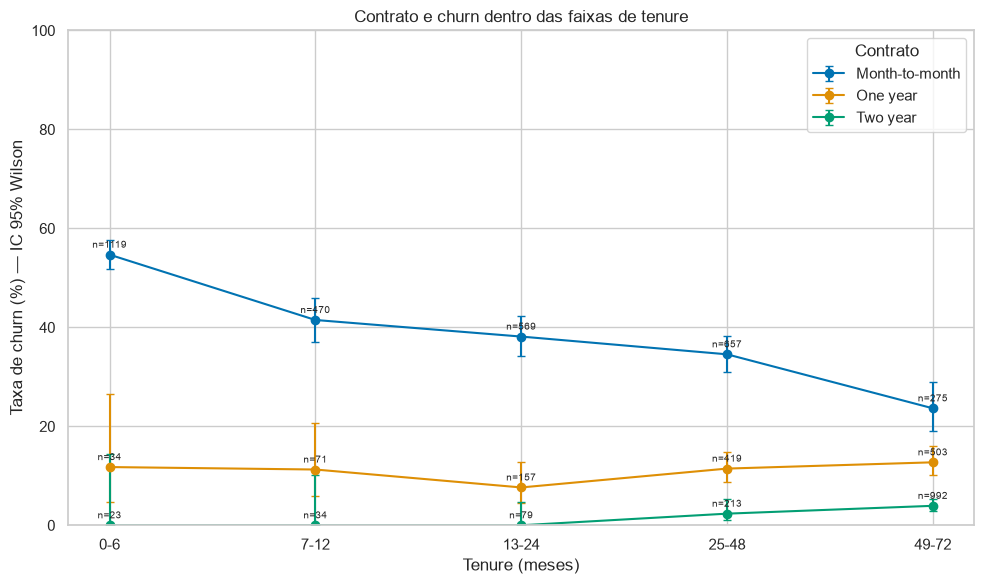

In [ ]:
Z_WILSON = 1.959963984540054

def intervalo_wilson(eventos, total):
    """Retorna os limites de Wilson em porcentagem para uma proporção binomial."""
    if total <= 0:
        return np.nan, np.nan
    p = eventos / total
    denominador = 1 + Z_WILSON**2 / total
    centro = (p + Z_WILSON**2 / (2 * total)) / denominador
    margem = Z_WILSON * np.sqrt(p * (1 - p) / total + Z_WILSON**2 / (4 * total**2)) / denominador
    return max(0.0, centro - margem) * 100, min(1.0, centro + margem) * 100

def resumo_churn(base, dimensoes):
    validos = base.dropna(subset=dimensoes + ['Churn'])
    tabela = (validos.groupby(dimensoes, observed=True, dropna=False)['Churn']
              .agg(total_grupo='size', cancelamentos=lambda valores: int(valores.eq('Yes').sum()))
              .reset_index())
    tabela['taxa_churn_pct'] = 100 * tabela['cancelamentos'] / tabela['total_grupo']
    limites = [intervalo_wilson(int(eventos), int(total))
               for eventos, total in zip(tabela['cancelamentos'], tabela['total_grupo'])]
    tabela['ic95_inf_pct'] = [limite[0] for limite in limites]
    tabela['ic95_sup_pct'] = [limite[1] for limite in limites]
    return tabela

def grafico_taxas(tabela, rotulo, titulo, caminho, limite=12):
    grafico = tabela.sort_values('taxa_churn_pct').tail(limite).copy()
    nomes = grafico[rotulo].astype(str) + ' (n=' + grafico['total_grupo'].astype(str) + ')'
    y = np.arange(len(grafico))
    valores = grafico['taxa_churn_pct'].to_numpy()
    erros = [valores - grafico['ic95_inf_pct'].to_numpy(), grafico['ic95_sup_pct'].to_numpy() - valores]
    fig, ax = plt.subplots(figsize=(10, max(4, 0.4 * len(grafico))))
    ax.barh(y, valores, color=sns.color_palette('colorblind')[0])
    ax.errorbar(valores, y, xerr=erros, fmt='none', color='black', capsize=3)
    ax.set_yticks(y, labels=nomes)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Taxa de churn (%) — IC 95% Wilson')
    ax.set_title(titulo)
    fig.tight_layout()
    fig.savefig(caminho, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Panorama de churn e cobrança mensal
panorama = resumo_churn(dados.assign(escopo='Todos os clientes'), ['escopo'])
panorama.to_csv(DIR_TABELAS / 'e2_panorama_churn_geral.csv', index=False)
cobranca = (dados.groupby('Churn', observed=True)['MonthlyCharges']
            .agg(n='count', media='mean', mediana='median', desvio_padrao='std').reset_index())
cobranca['cancelamentos'] = cobranca['Churn'].eq('Yes').astype(int) * cobranca['n']
cobranca['total_grupo'] = cobranca['n']
cobranca.to_csv(DIR_TABELAS / 'e2_monthlycharges_por_churn.csv', index=False)
display(panorama.round(2))
display(cobranca.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
row = panorama.iloc[0]
ax1.bar([0], [row['taxa_churn_pct']])
ax1.errorbar([0], [row['taxa_churn_pct']], yerr=[[row['taxa_churn_pct'] - row['ic95_inf_pct']], [row['ic95_sup_pct'] - row['taxa_churn_pct']]], fmt='none', color='black', capsize=4)
ax1.set_xticks([0], labels=[f"{int(row['cancelamentos'])}/{int(row['total_grupo'])}"])
ax1.set_ylim(0, 100)
ax1.set_ylabel('Taxa de churn (%) — IC 95% Wilson')
ax1.set_title('Panorama geral')
sns.boxplot(data=dados, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], ax=ax2)
ax2.set_ylabel('MonthlyCharges')
ax2.set_title('Cobrança mensal por situação observada')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'e2_panorama_churn_cobranca.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

# Faixas solicitadas
tenure_valido = dados.dropna(subset=['tenure']).copy()
n_excluidos_tenure = int(dados['tenure'].isna().sum())
assert len(tenure_valido) + n_excluidos_tenure == len(dados)
faixas = ['0-6', '7-12', '13-24', '25-48', '49-72']
tenure_valido['faixa_tenure'] = pd.cut(tenure_valido['tenure'].astype(int), bins=[-1, 6, 12, 24, 48, 72], labels=faixas, ordered=True, include_lowest=True)
assert tenure_valido['faixa_tenure'].notna().all()
print(f'N válido para tenure={len(tenure_valido)}')
por_tenure = resumo_churn(tenure_valido, ['faixa_tenure'])
por_tenure.to_csv(DIR_TABELAS / 'e2_churn_por_faixa_tenure.csv', index=False)
display(por_tenure.round(2))
grafico_taxas(por_tenure, 'faixa_tenure', 'Churn por faixa de tenure', DIR_GRAFICOS / 'e2_churn_por_faixa_tenure.png', limite=5)

contrato_tenure = resumo_churn(tenure_valido, ['faixa_tenure', 'Contract'])
contrato_tenure.to_csv(DIR_TABELAS / 'e2_churn_contrato_por_faixa_tenure.csv', index=False)
display(contrato_tenure.round(2))
fig, ax = plt.subplots(figsize=(10, 6))
posicoes = {faixa: i for i, faixa in enumerate(faixas)}
for contrato, grupo in contrato_tenure.groupby('Contract', observed=True):
    x = grupo['faixa_tenure'].astype(str).map(posicoes).to_numpy()
    y = grupo['taxa_churn_pct'].to_numpy()
    err = [y - grupo['ic95_inf_pct'].to_numpy(), grupo['ic95_sup_pct'].to_numpy() - y]
    ax.errorbar(x, y, yerr=err, marker='o', capsize=3, label=contrato)
    for xi, yi, n in zip(x, y, grupo['total_grupo']):
        ax.annotate(f'n={n}', (xi, yi), xytext=(0, 5), textcoords='offset points', ha='center', fontsize=7)
ax.set_xticks(range(len(faixas)), labels=faixas)
ax.set_ylim(0, 100)
ax.set_xlabel('Tenure (meses)')
ax.set_ylabel('Taxa de churn (%) — IC 95% Wilson')
ax.set_title('Contrato e churn dentro das faixas de tenure')
ax.legend(title='Contrato')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'e2_churn_contrato_por_faixa_tenure.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## Serviços, pagamento e características demográficas

Categorias estruturais (`No internet service`, `No phone service`) permanecem separadas. A contagem de proteção soma `Yes` nos quatro serviços `OnlineSecurity`, `OnlineBackup`, `DeviceProtection` e `TechSupport`, somente para `InternetService != 'No'` (4.401 clientes elegíveis). Diferenças entre grupos não são efeitos causais; contrato, tenure e perfil podem confundir essas associações.

,variavel,categoria,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct
0,PhoneService,No,563,143,25.40,21.98,29.15
1,PhoneService,Yes,5071,1361,26.84,25.64,28.08
2,MultipleLines,No,2704,674,24.93,23.33,26.59
3,MultipleLines,No phone service,563,143,25.40,21.98,29.15
4,MultipleLines,Yes,2367,687,29.02,27.23,30.89
5,InternetService,DSL,1924,373,19.39,17.68,21.21
6,InternetService,Fiber optic,2477,1042,42.07,40.14,44.02
7,InternetService,No,1233,89,7.22,5.90,8.80
8,OnlineSecurity,No,2803,1175,41.92,40.10,43.76
9,OnlineSecurity,No internet service,1233,89,7.22,5.90,8.80


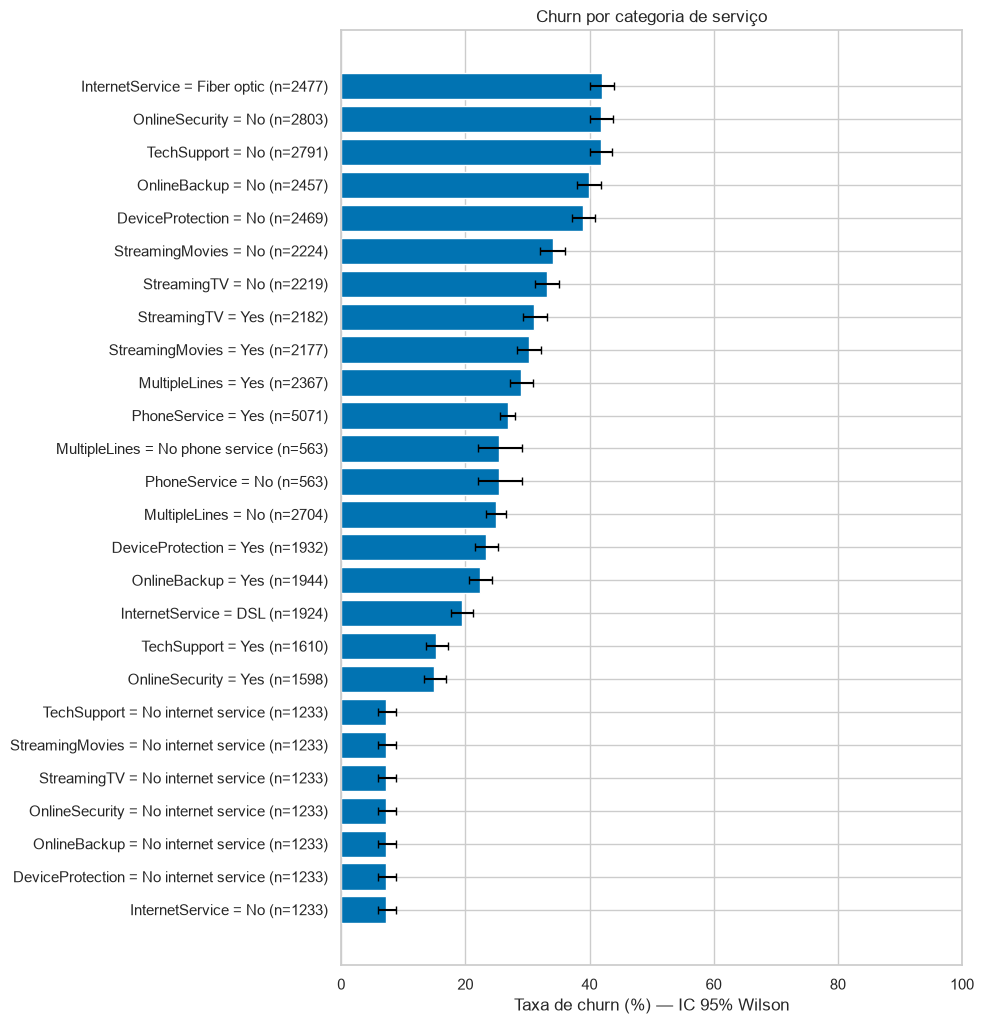

Elegíveis: 4,401; excluídos sem internet: 1,233.


,qtd_servicos_protecao,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct
0,0,1005,562,55.92,52.83,58.96
1,1,1189,472,39.70,36.95,42.51
2,2,1094,264,24.13,21.69,26.75
3,3,745,95,12.75,10.55,15.34
4,4,368,22,5.98,3.98,8.89


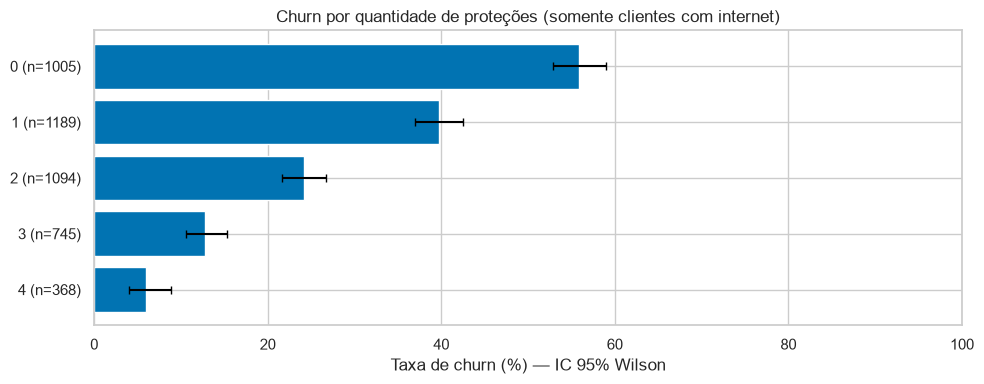

,variavel,categoria,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct
0,PaymentMethod,Bank transfer (automatic),1229,211,17.17,15.16,19.38
1,PaymentMethod,Credit card (automatic),1234,192,15.56,13.64,17.69
2,PaymentMethod,Electronic check,1888,852,45.13,42.89,47.38
3,PaymentMethod,Mailed check,1283,249,19.41,17.34,21.66
4,PaperlessBilling,No,2307,383,16.60,15.14,18.18
5,PaperlessBilling,Yes,3327,1121,33.69,32.11,35.32
6,gender,Female,2799,761,27.19,25.57,28.87
7,gender,Male,2835,743,26.21,24.62,27.86
8,SeniorCitizen,No,4706,1111,23.61,22.42,24.84
9,SeniorCitizen,Yes,928,393,42.35,39.21,45.55


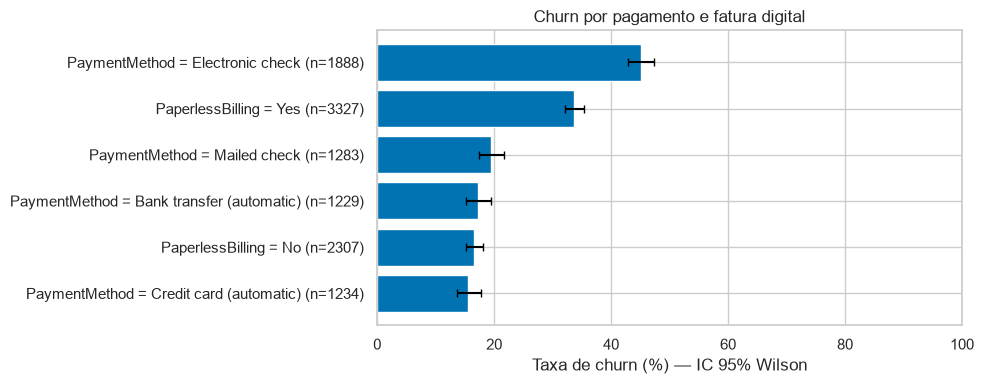

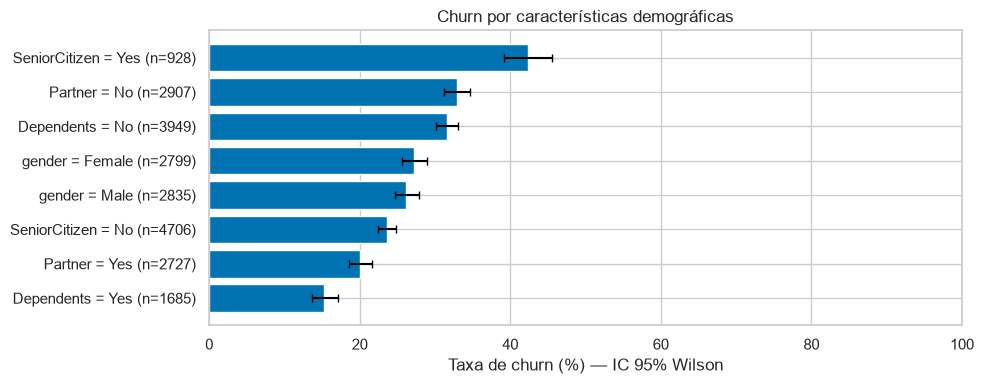

In [3]:
servicos = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
tabelas_servicos = []
for servico in servicos:
    tabela = resumo_churn(dados, [servico]).rename(columns={servico: 'categoria'})
    tabela.insert(0, 'variavel', servico)
    tabelas_servicos.append(tabela)
servicos_churn = pd.concat(tabelas_servicos, ignore_index=True)
servicos_churn['rotulo'] = servicos_churn['variavel'] + ' = ' + servicos_churn['categoria'].astype(str)
servicos_churn.to_csv(DIR_TABELAS / 'e2_servicos_por_churn.csv', index=False)
display(servicos_churn.drop(columns='rotulo').round(2))
grafico_taxas(servicos_churn, 'rotulo', 'Churn por categoria de serviço', DIR_GRAFICOS / 'e2_servicos_por_churn.png', limite=len(servicos_churn))

protecao = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
com_internet = dados.loc[dados['InternetService'].ne('No')].copy()
if len(com_internet) != 4401:
    raise ValueError(f'Esperados 4.401 clientes com internet; encontrados {len(com_internet)}. Verifique a Silver.')
if not com_internet[protecao].isin(['Yes', 'No']).all().all():
    raise ValueError('Categoria inesperada nos serviços de proteção elegíveis.')
com_internet['qtd_servicos_protecao'] = com_internet[protecao].eq('Yes').sum(axis=1)
por_protecao = resumo_churn(com_internet, ['qtd_servicos_protecao'])
por_protecao.to_csv(DIR_TABELAS / 'e2_servicos_protecao_por_churn.csv', index=False)
print(f"Elegíveis: {len(com_internet):,}; excluídos sem internet: {len(dados) - len(com_internet):,}.")
display(por_protecao.round(2))
grafico_taxas(por_protecao, 'qtd_servicos_protecao', 'Churn por quantidade de proteções (somente clientes com internet)', DIR_GRAFICOS / 'e2_servicos_protecao_por_churn.png', limite=5)

variaveis = ['PaymentMethod', 'PaperlessBilling', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']
tabelas_perfil = []
for variavel in variaveis:
    tabela = resumo_churn(dados, [variavel]).rename(columns={variavel: 'categoria'})
    tabela.insert(0, 'variavel', variavel)
    tabelas_perfil.append(tabela)
perfil_churn = pd.concat(tabelas_perfil, ignore_index=True)
perfil_churn['rotulo'] = perfil_churn['variavel'] + ' = ' + perfil_churn['categoria'].astype(str)
perfil_churn.to_csv(DIR_TABELAS / 'e2_pagamento_paperless_demografia.csv', index=False)
display(perfil_churn.drop(columns='rotulo').round(2))
pagamento = perfil_churn.loc[perfil_churn['variavel'].isin(['PaymentMethod', 'PaperlessBilling'])]
demografia = perfil_churn.loc[perfil_churn['variavel'].isin(['gender', 'SeniorCitizen', 'Partner', 'Dependents'])]
grafico_taxas(pagamento, 'rotulo', 'Churn por pagamento e fatura digital', DIR_GRAFICOS / 'e2_pagamento_paperless_por_churn.png', limite=len(pagamento))
grafico_taxas(demografia, 'rotulo', 'Churn por características demográficas', DIR_GRAFICOS / 'e2_demografia_por_churn.png', limite=len(demografia))

## Segmentos e exploração de CustomerFeedback

O ranking combina `Contract`, `InternetService`, `PaymentMethod` e `PaperlessBilling`. O ranking principal inclui grupos com N≥50; grupos menores ficam em arquivo separado e são apenas exploratórios. A amostra de `CustomerFeedback` foi inspecionada antes de definir os termos abaixo: os textos são narrativos e podem explicitar churn/cancelamento, portanto não são cruzados com churn nem usados para prever. As frequências lexicais são descritivas, podem se sobrepor e não identificam causas.

Grupos no ranking principal (N >= 50): 38; grupos menores separados: 34.


,Contract,InternetService,PaymentMethod,PaperlessBilling,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct,segmento
13,Month-to-month,Fiber optic,Electronic check,Yes,840,520,61.90,58.57,65.13,Month-to-month | Fiber optic | Electronic chec...
15,Month-to-month,Fiber optic,Mailed check,Yes,119,62,52.10,43.20,60.87,Month-to-month | Fiber optic | Mailed check | Yes
12,Month-to-month,Fiber optic,Electronic check,No,198,102,51.52,44.59,58.38,Month-to-month | Fiber optic | Electronic chec...
9,Month-to-month,Fiber optic,Bank transfer (automatic),Yes,196,100,51.02,44.07,57.93,Month-to-month | Fiber optic | Bank transfer (...
11,Month-to-month,Fiber optic,Credit card (automatic),Yes,193,85,44.04,37.22,51.09,Month-to-month | Fiber optic | Credit card (au...
5,Month-to-month,DSL,Electronic check,Yes,245,104,42.45,36.42,48.71,Month-to-month | DSL | Electronic check | Yes
4,Month-to-month,DSL,Electronic check,No,129,49,37.98,30.07,46.59,Month-to-month | DSL | Electronic check | No
7,Month-to-month,DSL,Mailed check,Yes,146,52,35.62,28.31,43.66,Month-to-month | DSL | Mailed check | Yes
2,Month-to-month,DSL,Credit card (automatic),No,57,20,35.09,24.00,48.06,Month-to-month | DSL | Credit card (automatic)...
8,Month-to-month,Fiber optic,Bank transfer (automatic),No,63,22,34.92,24.33,47.25,Month-to-month | Fiber optic | Bank transfer (...


Grupos abaixo do mínimo; interpretar somente como exploração:


,Contract,InternetService,PaymentMethod,PaperlessBilling,total_grupo,cancelamentos,taxa_churn_pct,ic95_inf_pct,ic95_sup_pct,segmento
14,Month-to-month,Fiber optic,Mailed check,No,45,22,48.89,34.96,63.00,Month-to-month | Fiber optic | Mailed check | No
10,Month-to-month,Fiber optic,Credit card (automatic),No,44,15,34.09,21.88,48.86,Month-to-month | Fiber optic | Credit card (au...
38,One year,Fiber optic,Mailed check,No,12,4,33.33,13.81,60.94,One year | Fiber optic | Mailed check | No
21,Month-to-month,No,Electronic check,Yes,24,6,25.00,12.00,44.90,Month-to-month | No | Electronic check | Yes
16,Month-to-month,No,Bank transfer (automatic),No,38,9,23.68,12.99,39.21,Month-to-month | No | Bank transfer (automatic...
36,One year,Fiber optic,Electronic check,No,38,9,23.68,12.99,39.21,One year | Fiber optic | Electronic check | No
19,Month-to-month,No,Credit card (automatic),Yes,19,3,15.79,5.52,37.57,Month-to-month | No | Credit card (automatic) ...
39,One year,Fiber optic,Mailed check,Yes,15,2,13.33,3.74,37.88,One year | Fiber optic | Mailed check | Yes
63,Two year,Fiber optic,Mailed check,Yes,9,1,11.11,1.99,43.50,Two year | Fiber optic | Mailed check | Yes
20,Month-to-month,No,Electronic check,No,28,3,10.71,3.71,27.20,Month-to-month | No | Electronic check | No


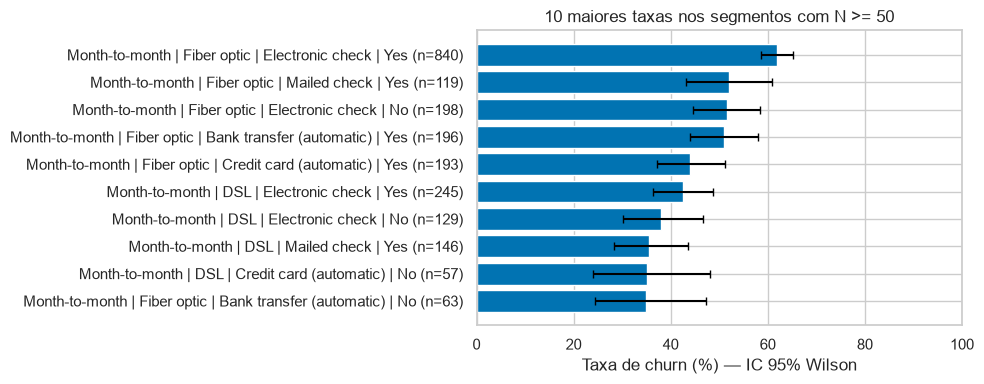

,n_textos,textos_unicos,duplicados_exatos,textos_vazios,comprimento_min,comprimento_mediano,comprimento_medio,comprimento_max
0,5634,5634,0,0,277,454.0,460.21,844


,topico,termos,textos_com_termo,total_textos,percentual_textos,limite
1,internet_qualidade,internet; dsl; fiber optic; speed; reliable; s...,5621,5634,99.77,"Busca literal; não identifica causa, sentiment..."
0,cobranca,monthly charge; charges; billing; bill; expens...,5548,5634,98.47,"Busca literal; não identifica causa, sentiment..."
3,pagamento,payment; paying; paid; credit card; bank trans...,5410,5634,96.02,"Busca literal; não identifica causa, sentiment..."
4,experiencia_satisfacao,satisfied; disappointed; issues; issue; proble...,5012,5634,88.96,"Busca literal; não identifica causa, sentiment..."
2,contrato,contract; month-to-month; one-year; two-year,2370,5634,42.07,"Busca literal; não identifica causa, sentiment..."


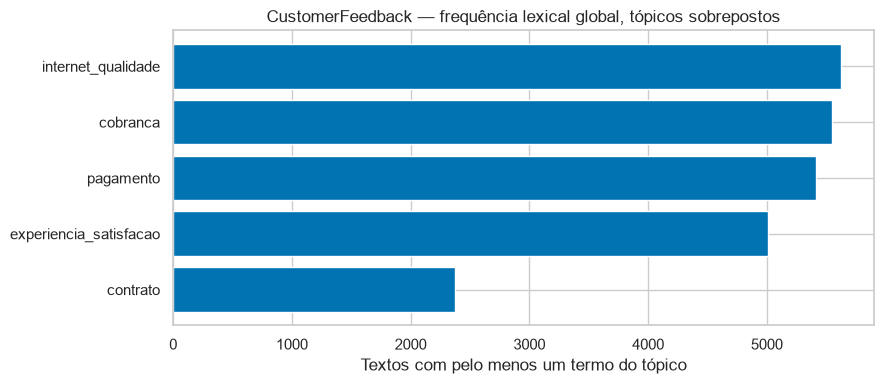

Lembrete: MonthlyIncome não foi interpretado como renda; MonthlyCharges tem unidade não confirmada; TotalCharges imputado não foi tratado como observado.


In [4]:
dimensoes_segmento = ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling']
segmentos = resumo_churn(dados, dimensoes_segmento)
segmentos['segmento'] = segmentos[dimensoes_segmento].astype(str).agg(' | '.join, axis=1)
ranking_principal = segmentos.loc[segmentos['total_grupo'].ge(50)].sort_values(['taxa_churn_pct', 'total_grupo'], ascending=[False, False]).copy()
grupos_pequenos = segmentos.loc[segmentos['total_grupo'].lt(50)].sort_values(['taxa_churn_pct', 'total_grupo'], ascending=[False, False]).copy()
ranking_principal.to_csv(DIR_TABELAS / 'e2_segmentos_churn_n_ge_50.csv', index=False)
grupos_pequenos.to_csv(DIR_TABELAS / 'e2_segmentos_churn_n_lt_50.csv', index=False)
print(f'Grupos no ranking principal (N >= 50): {len(ranking_principal)}; grupos menores separados: {len(grupos_pequenos)}.')
display(ranking_principal.head(10).round(2))
print('Grupos abaixo do mínimo; interpretar somente como exploração:')
display(grupos_pequenos.round(2))
grafico_taxas(ranking_principal.head(10), 'segmento', '10 maiores taxas nos segmentos com N >= 50', DIR_GRAFICOS / 'e2_segmentos_churn_top10.png', limite=10)

# Busca literal em tópicos escolhidos após inspecionar exemplos; sem classificação de causa/sentimento.
feedback = dados['CustomerFeedback'].dropna().astype(str)
perfil_feedback = pd.DataFrame([{
    'n_textos': len(feedback), 'textos_unicos': feedback.nunique(),
    'duplicados_exatos': int(feedback.duplicated().sum()),
    'textos_vazios': int(feedback.str.strip().eq('').sum()),
    'comprimento_min': int(feedback.str.len().min()),
    'comprimento_mediano': float(feedback.str.len().median()),
    'comprimento_medio': float(feedback.str.len().mean()),
    'comprimento_max': int(feedback.str.len().max()),
}])
perfil_feedback.to_csv(DIR_TABELAS / 'e2_customerfeedback_perfil.csv', index=False)
display(perfil_feedback.round(2))
topicos = {
    'cobranca': ['monthly charge', 'charges', 'billing', 'bill', 'expensive', 'steep', 'affordable'],
    'internet_qualidade': ['internet', 'dsl', 'fiber optic', 'speed', 'reliable', 'slow', 'connectivity'],
    'contrato': ['contract', 'month-to-month', 'one-year', 'two-year'],
    'pagamento': ['payment', 'paying', 'paid', 'credit card', 'bank transfer', 'electronic check', 'mailed check'],
    'experiencia_satisfacao': ['satisfied', 'disappointed', 'issues', 'issue', 'problem', 'problems'],
}
linhas_topicos = []
for topico, termos in topicos.items():
    padrao = '|'.join(termos)
    encontrados = int(feedback.str.contains(padrao, case=False, regex=True, na=False).sum())
    linhas_topicos.append({'topico': topico, 'termos': '; '.join(termos), 'textos_com_termo': encontrados, 'total_textos': len(feedback), 'percentual_textos': 100 * encontrados / len(feedback), 'limite': 'Busca literal; não identifica causa, sentimento ou risco de churn.'})
topicos_feedback = pd.DataFrame(linhas_topicos).sort_values('textos_com_termo', ascending=False)
topicos_feedback.to_csv(DIR_TABELAS / 'e2_customerfeedback_topicos.csv', index=False)
display(topicos_feedback.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
grafico = topicos_feedback.sort_values('textos_com_termo')
ax.barh(grafico['topico'], grafico['textos_com_termo'])
ax.set_xlabel('Textos com pelo menos um termo do tópico')
ax.set_title('CustomerFeedback — frequência lexical global, tópicos sobrepostos')
fig.tight_layout()
fig.savefig(DIR_GRAFICOS / 'e2_customerfeedback_topicos.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Lembrete: MonthlyIncome não foi interpretado como renda; MonthlyCharges tem unidade não confirmada; TotalCharges imputado não foi tratado como observado.')